# Lecture 20: Finite Volume Methods and Conservation Laws with Partial Differential Equations

When we solve partial differential equations, we don't want quantities flowing into and out of our system due to the algorithm, rather than the physics. For instance, we don't want mass, momentum, and energy being injected into our system by the way we are calculating the solution to our equations. This lecture develops discritization algorithms that explicitly conserves quantities we are interested in.

In addition to the lecture material below, all students also need to download `lec20_module.py` using the command below:
```bash
curl -O ***
```

### Accepting and submitting

To accept this assignment on Classroom 50 with your GitHub profile enrolled in the class, click on the link \
https://classroom50.org/PsuAstro410/410astro26/assignments/lecture-20/accept \
and follow the steps the webpage prompts.

To submit this assignment, follow the steps in "First time Classroom 50 setup" and "Accepting and Submitting Assignments" on the course webpage:\
https://psuastro410.github.io/tips/github/

### Resources and Acknowledgements

We have used material from the following sources: \
https://zingale.github.io/computational_astrophysics/advection/advection/advection-finite-volumes.html \
https://zingale.github.io/computational_astrophysics/advection/burgers/burgers.html \
https://zingale.github.io/computational_astrophysics/euler/euler.html \

We also thank Shane Davis for material that went into the design of this lecture.

In [23]:
## Nice things to have this lecture
import matplotlib.pyplot as plt
import numpy as np
import lec20_module as pdemod

# Finite-Volume Discretization

Ultimately we are interested in conservation laws, so we want a method
that respects conservation.  We'll look at this with advection first, where we solve the partial differential equation

$$\frac{\partial a}{\partial t} + u \frac{\partial a}{\partial x} = 0$$


Here we see 3 different types of grids:

![discretization types](https://zingale.github.io/computational_astrophysics/_images/grids.png)

The first 2 are *finite-difference* grids&mdash;the data is
represented at a specific point in the domain.  The two differ in that
the second case is a cell-centered finite-difference grid.  In this
case, there is not a point on the physical boundaries, while with the
first example (what we were using previously), there is a data point
on each boundary.  For the cell-centered case, we typically talk about
dividing the data into cells or zones and the data living at the
center of the zone.

The last example is a *finite-volume* grid.  Here, we don't think of
the data living at a specific point, but instead we keep track of the
total amount of a quantity (or its average) in a volume.  This is
represented above as the shaded region inside our zone.

**Note:**
We often use the terms _zone_, _cell_, and _volume_ interchangeably. We also use half-integer indices to denote the location of the boundaries of
a volume, so:

$$x_{i-1/2} = x_i - \frac{\Delta x}{2}$$

and the volume represented by $i$ extends from $[x_{i-1/2}, x_{i+1/2}]$.

## Cell-averages

Imagine we have a function $f(x)$ that we wish to represent on our grid, using a finite-volume discretization.

![finite-volume grid](https://zingale.github.io/computational_astrophysics/_images/fv_grid.png)

We can define the average of $f(x)$ in a zone that goes from
$x_{i-1/2}$ to $x_{i+1/2}$ as:

$$\langle f\rangle_i = \frac{1}{\Delta x} \int_{x_{i-1/2}}^{x_{i+1/2}}f(x) dx$$

We use the angle brackets to indicate that this is an average, and use
an integer index, $i$, to indicate that this data lives in zone $i$.

Now consider our linear advection equation,

$$\frac{\partial a}{\partial t} = -u\frac{\partial a}{\partial x}$$

written in conservative form:

$$\frac{\partial a}{\partial t} = -\frac{\partial F(a)}{\partial x}$$

where $F(a) = ua$ is the flux.

Let's average (integrate) this equation over a zone (from $[x_{i-1/2},
x_{i+1/2}]$):

$$\frac{1}{\Delta x} \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial a}{\partial t} dx =
   -\frac{1}{\Delta x} \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial F}{\partial x} dx$$

we can recognize the left is the time-derivative of the average of $a$
and the right, via the divergence theorem is just the flux different
through the boundary of the zone:

$$\frac{\partial}{\partial t} \langle a\rangle_i = -\frac{1}{\Delta x}
   \left [ F_{i+1/2} - F_{i-1/2} \right ]$$

Here, $F_{i-1/2}$ indicates the flux moving through the interface at location $x_{i-1/2}$.

**Note:**
Finite-volume method are conservative because the flux leaving one volume enters
the adjacent zone.

For example, in the updates for zones $i-1$ and $i$, we have:

$$\frac{\partial}{\partial t} \langle a\rangle_{i-1} = -\frac{1}{\Delta x}
   \left [ F_{i-1/2} - F_{i-3/2} \right ]$$

$$\frac{\partial}{\partial t} \langle a\rangle_i = -\frac{1}{\Delta x}
   \left [ F_{i+1/2} - F_{i-1/2} \right ]$$

So any amount of $\langle a\rangle_{i-1}$ that leaves zone $i-1$ through the right interface is gained
by $\langle a\rangle_i$ by that same flux entering through its left interface.  This is an
example of a [telescoping sum](https://en.wikipedia.org/wiki/Telescoping_series).

## Time update

Let's start with a first-order update in time.  We can use the Euler
method we already saw,

$$\frac{\partial \langle a \rangle}{\partial t} \approx \frac{\langle a\rangle^{n+1} - \langle a\rangle^{n}}{\Delta t}$$

in which case our update appears as:

$$\langle a\rangle_i^{n+1} = \langle a\rangle_i^{n} - \frac{\Delta t}{\Delta x} (F_{i+1/2}^n - F_{i-1/2}^n)$$

We expect this to be first order accurate in time.  Notice that the
fluxes are evaluated at the old time.


## Reconstruction and the Riemann problem

We need the value of the flux on the interface, $F_{i+1/2}$, we find this using the analytic expression
for the flux, $F(a)$, as:

$$[F(a)]_{i+1/2} = F(a_{i+1/2})$$

So now we need to find the interface state, $a_{i+1/2}$.  

Getting the value of $a$ on the interface from the average, $\langle a
\rangle$ is called *reconstruction*.  It means we need to infer how
$a$ actually varies throughout the cell just from the information we
have about its average value.  There are a variety of methods we can
use (some of which we will explore later).  For now, we will do the
simplest, and assume that $a(x)$ is constant in each cell:

$$a_{i+1/2,L} = \langle a\rangle_i^n$$
$$a_{i+1/2,R} = \langle a\rangle_{i+1}^n$$

Notice that we actually have 2 values for the interface state when we
do this, one coming from each side of the interface&mdash;we label
these as the left and right states:

![left and right states for advection](https://zingale.github.io/computational_astrophysics/_images/riemann-adv-mol.png)

Now we need to resolve this degeneracy&mdash;which of the two states
(or what combination of them) is the correct interface state?  This is called the
*Riemann problem*.

**Note:**
The Riemann problem is where the physics of the actual set of equations
comes into play.  Thus far, everything we've done has been general.

For advection, the Riemann problem is easy.  We know that for 
$u > 0$ that $a(x)$ moves
from left to right, so the correct state on the interface is the left
state&mdash;this is upwinding.

$$
a_{i+1/2} = \mathcal{R}(a_{i+1/2,L}, a_{i+1/2,R}) = 
\left \{ 
\begin{array}{c}
 a_{i+1/2,L} \quad u > 0 \\
 a_{i+1/2,R} \quad u < 0 
\end{array}
\right .
$$

where we indicate the Riemann problem as
$\mathcal{R}(a_{i+1/2,L},a_{i+1/2,R})$.

For the advection equation, with $u > 0$, our interface states are 

$$F_{i+1/2} = F(a_{i+1/2}) = u a_{i+1/2} = u \langle a \rangle_i$$

$$F_{i-1/2} = F(a_{i-1/2}) = u a_{i-1/2} = u \langle a \rangle_{i-1}$$

Inserting these into our difference equation, we have:

$$\langle a \rangle_i^{n+1} = \langle a \rangle_i^n - \frac{u \Delta t}{\Delta x} (\langle a \rangle_i^n - \langle a \rangle_{i-1}^n)$$

This is precisely the upwind finite-difference scheme we saw earlier.


# Burgers' Equation

The [inviscid Burgers' equation](https://en.wikipedia.org/wiki/Burgers%27_equation#Inviscid_Burgers'_equation) is the simplest nonlinear wave
equation, and serves as a great stepping-stone toward doing full
hydrodynamics.

$$u_t + u u_x = 0$$

**Note:**
This looks like the linear advection equation, except the quantity
being advected is the velocity itself.  This means that $u$ is no
longer a constant, but can vary in space and time.

Written in conservative form, 

$$\frac{\partial u}{\partial t} + \frac{\partial F(u)}{\partial x} = 0$$

it appears as:

$$u_t + \left [ \frac{1}{2} u^2 \right ]_x = 0$$

so the flux is $F(u) = \frac{1}{2} u^2$.

In the finite volume approach, we integrate over the volume of a cell
to get the update:

$$\frac{\partial \langle u \rangle_i}{\partial t} = - \frac{1}{\Delta x} (F_{i+1/2} - F_{i-1/2})$$

To second order accuracy, as we saw previously, $\langle u \rangle_i
\approx u_i$, so we'll drop the $\langle \rangle$ here.

**Important:**
By solving Burgers' equation in integral form (which is what the finite-volume
approach does), we avoid needing to discretize $\partial u/\partial x$ directly,
which may be undefined if $u$ is discontinuous.

In the finite difference form, we explicitly advance each timestep via
$$
u_i^{n+1} = u_i^n - \frac{\Delta t}{\Delta x}(F_{i+1/2} - F_{i-1/2})
$$

### Ghost Cells and Boundary Conditions

Finite volume methods usually compute fluxes based on values of variables in neighboring cell on either side of the interface.  This means that values outside the simulation domain will have to be used on boundaries.  Most implementations approach this by having a combination of active cells and ghost cells.  **Active cells** are the ones being updated by the integration method.  **Ghost cells**, in constrast, are on the boundaries and specified by the boundary conditions.  A first order method requires at least one ghost cell and higher order methods usually require more ghost cells as they use more neighboring cells to represent the values at the interfaces.

Let's consider the following example, a domain with $N$ active cells which has two ghost cells at each end of the domain for a total of $N+4$ cells.
<table>
  <tr>
    <td colspan="2" style="text-align:center;border-right-style:solid;">ghost cells</td>
    <td colspan="5" style="text-align:center;">active cells</td>
    <td colspan="2" style="text-align:center;border-left-style:solid;">ghost cells</td>
  </tr>
  <tr>
    <td width="40em">$u_0$</td>
    <td width="40em" style="border-right-style:solid;">$u_1$</td>
    <td width="40em">$u_2$</td>
    <td width="40em">$u_3$</td>
    <td width="40em">$\dots$</td>
    <td width="40em">$u_N$</td>
    <td width="40em">$u_{N+1}$</td>
    <td width="40em" style="border-left-style:solid;">$u_{N+2}$</td>
    <td width="40em">$u_{N+3}$</td>
  </tr>
</table>

In this case, our boundary condtion must specify the value of $u_0$, $u_1$, $u_{N+2}$ and $u_{N+3}$.  For example in periodic boundary conditions we would choose
$$
u_0 = u_N, ~~ u_1 = u_{N+1}, ~~ u_{N+2} = u_2, ~~ u_{N+3} = u_3
$$

### Burger's equation revisited

Last weeek we solved Burgers equation in flux conservative form as
$$
\frac{\partial u}{\partial t}+\frac{\partial}{\partial x}\left(\frac{u^2}{2}\right)=0,
$$
Since this is conservative, we can use a finite volume representation of the form
$$
u_i^{n+1} = u_i^n - \frac{\Delta t}{\Delta x}(F_{i+1/2} - F_{i-1/2})
$$

We can specify $F_{i \pm 1/2}$ using a simple upwind method e.g.
$$
F_{i-1/2} = \frac{(u_{i-1}^n)^2}{2} ~~ {\rm if}~~ u_{i-1/2}^n > 0,
$$
or
$$
F_{i-1/2} = \frac{(u_i^n)^2}{2} ~~ {\rm if}~~ u_{i-1/2}^n \le 0,
$$
and $u_{i-1/2}= (u_{i-1}+u_i)/2$.

Lets try implementing below. I will give you the functions to intialize and obtain the fluxes.

In [1]:
def initial_gaussian(g):
    """ Initialize profile """
    g.u = 0.2 + 0.8 * np.exp(-0.5 * g.x**2)
    return g

def flux_upwind(ul, ur):
    """ solve rieman problem for burgers using upwind """

    # use the average ul and ur to determine direction
    ua = 0.5*(ul+ur)
    if ua > 0:
        return ul**2/2
    else:
        return ur**2/2

time: 0.0, integral: 1.77
time: 8.0, integral: 1.77
time: 32.0, integral: 1.77
time: 128.0, integral: 1.77


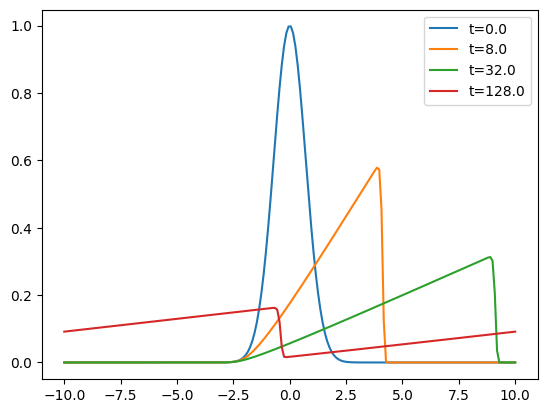

In [26]:
def initial_gaussian(g):
    g.u[:] = np.exp(-g.x**2)

fig, ax = plt.subplots()
nx = 200

for tval in [0.0, 8.0, 32.0, 128.0]:
    g = pdemod.burgers_fv(nx, C=0.5, tmax=tval, init_cond=initial_gaussian)
    x = g.x[g.ilo:g.ihi+1]
    u = g.u[g.ilo:g.ihi+1]
    ax.plot(x, u, label=f"t={tval:.1f}")
    print(f"time: {tval:.1f}, integral: {g.u[g.ilo:g.ihi].sum()*g.dx:.2f}")

ax.legend()
plt.show()

We see that a sum over all $u$ on the active (evolving) grid yields the same value to machine precision. The finite volume approach enforces the conservative nature of the PDE.

What if we had differenced it in another way?  One could also have performed a simple finite difference on $u$ directly and then multiplied by $u$ e.g.:
$$
\left(\frac{\partial u}{\partial x}\right)^n =\frac{u_{i}^n-u_{i-1}^n}{\Delta x} ~~ {\rm if}~~ u_{i}^n>0,
$$
$$
\left(\frac{\partial u}{\partial x}\right)^n=\frac{u_{i+1}^n-u_{i}^n}{\Delta x} ~~ {\rm if}~~ u_{i}^n<0.
$$
The update then follows from
$$
u_i^{n+1}=u_i^n-u_i^n \Delta t \left(\frac{\partial u}{\partial x}\right)^n
$$

The operator corresponding to the spatial derivative is formally the same mathematically, but as we have already learned, that does not mean the discretization will yield the same results.  Lets try it out.

time: 0.0, integral: 1.77
time: 8.0, integral: 0.90
time: 32.0, integral: 0.37
time: 128.0, integral: 0.13


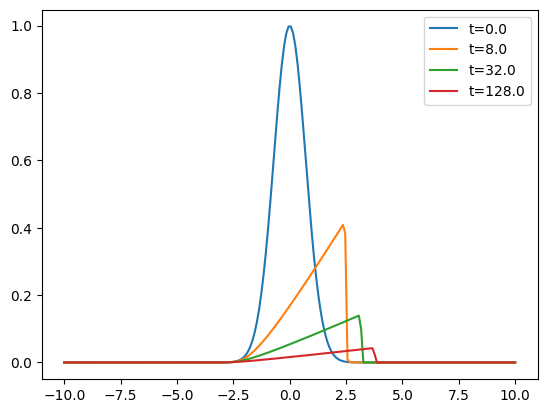

In [25]:
fig, ax = plt.subplots()
nx = 200

for tval in [0.0, 8.0, 32.0, 128.0]:
    g = pdemod.burgers_upwind_nc(nx, C=0.5, tmax=tval, init_cond=initial_gaussian)
    x = g.x[g.ilo:g.ihi+1]
    u = g.u[g.ilo:g.ihi+1]
    ax.plot(x, u, label=f"t={tval:.1f}")
    print(f"time: {tval:.1f}, integral: {g.u[g.ilo:g.ihi].sum()*g.dx:.2f}")

ax.legend()
plt.show()

The evolution looks qualitatively similar in the two approaches, but we see that the amplitude is lower and the profile hasn't shifted as far in the last case.  We see via the sum over $u$, that $u$ is decreasing with time, indicating that amplitude is dropping. Choosing your discretization to enforce conservation can have a significant impact!  Since conservations laws are so important in physics (e.g. cons. of mass, momentum, and energy), this feature makes finite volume algorithms very popular.

# Euler Equations

The Euler equations describe compressible flow in the absence of
dissipative effects (like viscosity).  In one-dimension, they appear
as:

\begin{align*}
&\frac{\partial \rho}{\partial t} + \frac{\partial (\rho u)}{\partial x} = 0 \\
&\frac{\partial (\rho u)}{\partial t} + \frac{\partial}{\partial x} (\rho u^2 + p) = 0 \\
&\frac{\partial (\rho E)}{\partial t} + \frac{\partial}{\partial x} \left [ (\rho E + p) u \right ] = 0
\end{align*}

Here, $E$ is the specific total energy which is related to the specific internal energy as:

$$
\rho E = \rho e + \frac{1}{2} \rho u^2
$$

and the system is closed by an equation of state:

$$p = p(\rho, e)$$

A common equation of state is a *gamma-law EOS*:

$$ p = \rho e (\gamma - 1)$$

where $\gamma$ is a constant.  For an ideal gas, $\gamma$ is the ratio of specific heats, $c_p / c_v$.


## Conservative form

As expressed above, the Euler equations are in conservative form.  We can define the conservative
state, ${\bf U}$ as:

$${\bf U} = \left ( \begin{array}{c} \rho \\ \rho u \\ \rho E \end{array} \right )$$

and the flux, ${\bf F}({\bf U})$ as:

$${\bf F} = \left ( \begin{array}{c} \rho u \\ \rho u^2 + p  \\ (\rho E + p) u \end{array} \right )$$

and then our system in conservative form is:

$${\bf U}_t + [{\bf F}({\bf U})]_x = 0$$

and we can do the same technique of discretizing the domain into cells
and integrating over the volume of a cell to get the finite-volume
conservative update for the system:

$$\frac{\partial {\bf U}_i}{\partial t} =
  - \frac{1}{\Delta x} \left [ {\bf F}({\bf U}_{i+1/2}) - {\bf F}({\bf U}_{i-1/2}) \right ]$$

This means that we will be able to use the same basic solution methodology
from advection and Burgers' equation with the Euler equations, so long
as we can find the fluxes.  This primarily means that we need to understand the Riemann
problem for the Euler equations.

## Primitive variable form

We can alternately express the Euler equations in terms of the primitive variables, ${\bf w}$:

$${\bf w} = \left ( \begin{array}{c} \rho \\ u \\ p \end{array} \right )$$

and the evolution equations are:

$$
\left ( \begin{array}{c} \rho \\ u \\ p \end{array} \right )_t +
   \left ( \begin{array}{c} u & \rho & 0 \\ 0 & u & 1/\rho \\ 0 & \gamma p & u \end{array} \right )
   \left ( \begin{array}{c} \rho \\ u \\ p \end{array} \right )_x = 0
$$


or compactly:

$${\bf w}_t + {\bf A}({\bf w}) {\bf w}_x = 0$$

Another useful quantity is the speed of sound, defined as:

$$c = \sqrt{\frac{\gamma p}{\rho}}$$

## Riemann problem in fluids

In fluid dynamics, the Riemann problem is usually treated as follows: one assume a discontinuity in the variables at the interface between two cells.  One uses a reconstruction method to determine the left and right states on either side of this discontinuity, and then solves for how such a discontinuity would evolve. The details require a bit more work to understand, so we will skip over them. They are included in the function `rsolver`.

This approach provides accurate evolution, even when shocks develop in the flow.  There are many methods to solve the problem efficiently but approximately. It can be shown that approximate solutions can be almost as good as the more exact solution, but are considerably less computationally expensive. We provide here one solution, called the **Roe solver**, which uses a linear approximation of the system while correctly capturing the shock structure if shocks are present.  If you are interested in understanding these solution better, you can find more information here:

https://www.ita.uni-heidelberg.de/~dullemond/lectures/num_fluid_2011/Chapter_6.pdf

https://www.ita.uni-heidelberg.de/~dullemond/lectures/num_fluid_2011/Chapter_7.pdf

Since coding up the Roe solver is a bit more complicated, I wll just give it to you, but review the code to understand what it is doing.

Finally, we note that we still have a time-step constraint, which is correspond to the CFL condition.  In this case, we are assuming that the Riemann problems on opposite sides of the cell are independent for the duration of the time step so that the fluxes can be computed independently.  This is accomplished by determining the fastest propagation speed, which corresponds to the sum of advection velociy and gas sound speed: $c_{\rm max} = |u + \sqrt{\gamma p/\rho}|$.  We then require that
$$
\Delta t = C \Delta x / c_{\rm max}
$$
with $C$ being the CFL numbera and $C \le 1$.

# Exercises (10 pt)

## Exercise 1 - Muddiest Moment

What was the most confusing part of this lecture?

**Answer here**

### Exercise 2: Shock-tube (8 pt)

Let's try this on a specific example. Consider a **shock tube**, in which a 1D pipe is separated by a divider at $x = 0$ into two compartments and the divider is suddenly removed at $t = 0$.  Write your initial conditions as follows.

\begin{aligned}
  \rho = 3, u = 0, p = 3, \quad & \textrm{if}\ x < 0,\\
  \rho = 1, u = 0, p = 1, \quad & \textrm{if}\ x > 0.
\end{aligned}
The case where each state is uniform and the flow velocity is initially zero everywhere can be solved analytically (or semi-analytically with a root find) and is commonly used for testing hydro code e.g. the Sod shock tube: https://en.wikipedia.org/wiki/Sod_shock_tube

Note that this system is not periodic, so we need to used different boundary conditions than we did above for solving Burger's equation. Let's try the following
$$
U_0= U_1, ~~ U_{N+2} = U_{N+1}.
$$
In other words, we copy the values in the last active cell before boundary out into the ghost cell(s).  This boundary condition is an example of an open boundary condition.

We will also use a computational domain of $-2 \le x \le 2$, $n_x = 200$ grid cells, and run the code up to $t = 1$.

### Exercise 2(a) - Initial condition (2 pt)

Write a function that takes as an input the grid, sets the density, velocity, and pressure equal to the initial conditions using `g.rho[:]`, `g.u[:]`, and `g.p[:]`, using `np.where`.

In [17]:
### Answer here


### Exercise 2(b) - Look for flux updating step (2 pt)

Look through `lec20_module.py` for the step that calculates the flux at the interface steps. Copy this code, and include it in the markdown cell below using `<code>`.

**Answer here**

### Exercise 2(c) - Look for variable update timestep (2 pt)

Look through `lec20_module.py` that updates the convervative variable vector ${\bf U}$. Copy this code, and include it in the markdown cell below using `<code>`.

**Answer here**

### Exercise 2(d) - Run the code, and plot the solution.

Run `pdemod.euler_fv` up to times $t = 0, 0.5, 1.0$, and plot $\rho$, $u$, and $p$, modifying the code below.

time: 0.00, integral: 7.98
time: 0.50, integral: 7.98
time: 1.00, integral: 7.98


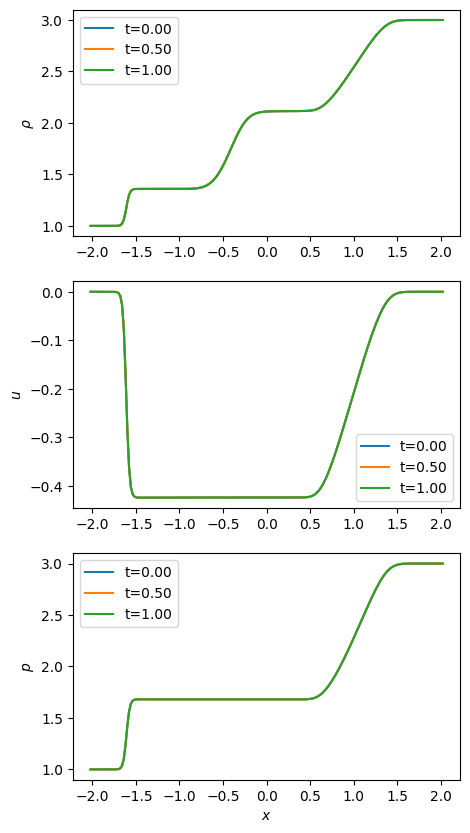

In [22]:
fig, ax = plt.subplots(3, 1, figsize=(5,10))
nx = 200

for tval in [0.0, 0.5, 1.0]:
    # command to run pdemod.euler_fv
    ax[0].plot(g.x, g.rho, label=f"t={tval:.2f}")
    ax[1].plot(g.x, g.u, label=f"t={tval:.2f}")
    ax[2].plot(g.x, g.p, label=f"t={tval:.2f}")
    print(f"time: {tval:.2f}, integral: {g.rho[g.ilo:g.ihi].sum()*g.dx:.2f}")
    
for i in range(3):
    ax[i].legend()

ax[2].set_xlabel('$x$')
ax[0].set_ylabel(r'$\rho$')
ax[1].set_ylabel('$u$')
ax[2].set_ylabel('$p$')

plt.show()